# 01 · Exploratory Data Analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cecile1015/emotion-mirror-cbs4702/blob/main/notebooks/01_eda.ipynb)

**Dataset:** [dair-ai/emotion](https://huggingface.co/datasets/dair-ai/emotion) (Saravia et al., 2018) — 20,000 English texts labelled with one of six emotions: *sadness (0), joy (1), love (2), anger (3), fear (4), surprise (5)*.

This notebook characterises the data before any model is trained. Each analysis ends with a short note on how the finding affects model development.

| § | Analysis | Question |
|---|---|---|
| 1 | Loading and integrity checks | Are the splits complete and well-formed? |
| 2 | Label distribution | How imbalanced are the classes, and are the splits comparable? |
| 3 | Text length | How long are the texts, and does length differ by emotion? |
| 4 | Vocabulary and Zipf's law | How sparse is the vocabulary, and how many unseen words occur at test time? |
| 5 | Frequent vs. distinctive words | Which words characterise each emotion? |
| 6 | Lexical templates | Does the data-collection method leave a trace in the texts? |
| 7 | Duplicates and split overlap | Is there label noise or leakage between splits? |
| 8 | Difficult examples and slices | Which texts, emotion pairs and text types (template, negation) are hard to classify? |
| 9 | Evaluation sanity check | What score does a trivial classifier obtain? |
| 10 | Summary | What do the findings imply for the models? |

Test labels are never used for any modelling decision; they appear only once, in the descriptive comparison of label shares across splits (§2). Test texts are used only for descriptive checks (text length, vocabulary coverage, overlap counts).

In [18]:
# Environment setup: runs locally (from the project root or notebooks/) and on Google Colab.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Cecile1015/emotion-mirror-cbs4702.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab already provides every package this notebook needs; only the repository is cloned.
    ROOT = Path("/content/emotion-mirror-cbs4702")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT / "notebooks")
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT} | running on Colab: {IN_COLAB}")

Project root: /Users/yin/Desktop/6-polyu year3 semester1/CBS4702 Advanced Topics in Quantitative Language Studies/emotion-mirror-cbs4702 | running on Colab: False


In [19]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency, kruskal
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

from src.config import EMOTION_COLORS, FIG_DIR, LABELS, SEED, ensure_dirs, set_seed
from src.data import load_splits, tokenize
from src.evaluate import emotion_palette, evaluate, per_class_table, plot_confusion_matrix

set_seed(SEED)
ensure_dirs()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
PALETTE = emotion_palette()
pd.set_option("display.max_colwidth", 120)


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")

## 1. Loading and integrity checks

The three official splits are downloaded once and cached in `data/` (see `src/data.py`). `load_split` also validates the schema: no missing texts and all labels within 0–5.

In [3]:
splits = load_splits()
train, val, test = splits["train"], splits["validation"], splits["test"]

for name, df in splits.items():
    n_empty = int((df["text"].str.strip() == "").sum())
    print(f"{name:<11} {len(df):>6,} rows | empty texts: {n_empty} | label ids: {sorted(int(x) for x in df['label'].unique())}")

train.sample(8, random_state=SEED)[["text", "label", "label_name"]]

train       16,000 rows | empty texts: 0 | label ids: [0, 1, 2, 3, 4, 5]
validation   2,000 rows | empty texts: 0 | label ids: [0, 1, 2, 3, 4, 5]
test         2,000 rows | empty texts: 0 | label ids: [0, 1, 2, 3, 4, 5]


,text,label,label_name
8756,ive made it through a week i just feel beaten down,0,sadness
4660,i feel this strategy is worthwhile,1,joy
6095,i feel so worthless and weak what does he have to say that s what i want to find out,0,sadness
304,i feel clever nov,1,joy
8241,im moved in ive been feeling kind of gloomy,0,sadness
9577,i allowed myself to feel the really shitty feelings while i was running because a the endorphins were flowing so it ...,0,sadness
1035,i feel confused too,4,fear
9976,i feel like a crappy mummy if were stuck in but there are days where i really cant face much else then venturing out...,0,sadness


## 2. Label distribution

The class balance determines the evaluation metric and whether class weighting is needed. A χ² test of homogeneity checks whether the three splits share the same label distribution.

count                 share (%)                 
           train validation test     train validation  test
label_name                                                 
sadness     4666        550  581      29.2       27.5  29.0
joy         5362        704  695      33.5       35.2  34.8
love        1304        178  159       8.2        8.9   8.0
anger       2159        275  275      13.5       13.8  13.8
fear        1937        212  224      12.1       10.6  11.2
surprise     572         81   66       3.6        4.0   3.3

Imbalance ratio (largest / smallest class, train): 9.4
Chi-squared test of homogeneity across splits: chi2 = 11.21, p = 0.341


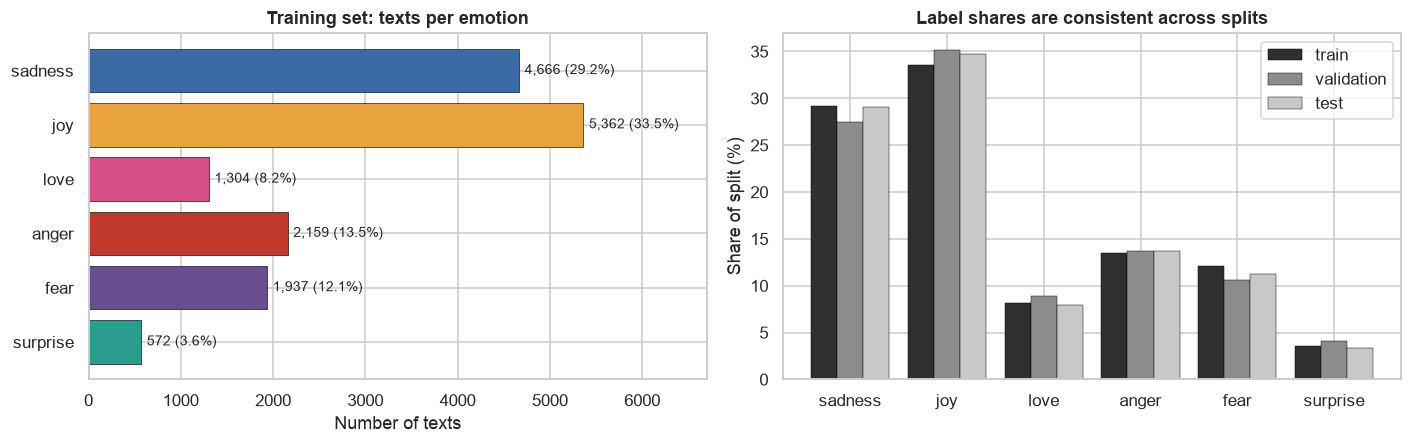

In [4]:
dist = pd.DataFrame({name: df["label_name"].value_counts().reindex(LABELS) for name, df in splits.items()})
share = dist / dist.sum()
display(pd.concat({"count": dist, "share (%)": (share * 100).round(1)}, axis=1))

imbalance_ratio = dist["train"].max() / dist["train"].min()
chi2_stat, chi2_p, _, _ = chi2_contingency(dist.values)
print(f"Imbalance ratio (largest / smallest class, train): {imbalance_ratio:.1f}")
print(f"Chi-squared test of homogeneity across splits: chi2 = {chi2_stat:.2f}, p = {chi2_p:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
bars = ax.barh(LABELS[::-1], dist["train"][::-1], color=PALETTE[::-1], edgecolor="black", linewidth=0.4)
for bar, n, s in zip(bars, dist["train"][::-1], share["train"][::-1]):
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height() / 2, f"{n:,} ({s:.1%})", va="center", fontsize=9)
ax.set_xlim(0, dist["train"].max() * 1.25)
ax.set_xlabel("Number of texts")
ax.set_title("Training set: texts per emotion")

ax = axes[1]
x = np.arange(len(LABELS))
for k, (name, shade) in enumerate(zip(splits, ["#2F2F2F", "#8C8C8C", "#C8C8C8"])):
    ax.bar(x + (k - 1) * 0.27, share[name] * 100, 0.27, label=name, color=shade, edgecolor="black", linewidth=0.3)
ax.set_xticks(x, LABELS)
ax.set_ylabel("Share of split (%)")
ax.set_title("Label shares are consistent across splits")
ax.legend()
fig.tight_layout()
savefig(fig, "eda_label_distribution.png")
plt.show()

**Implication.** The classes are clearly imbalanced: *joy* (33.5%) and *sadness* (29.2%) together make up 62.7% of the training set, while *love* (8.2%) and *surprise* (3.6%) are minority classes; the largest class is 9.4 times the size of the smallest. A model that ignores the minority classes can still obtain a high accuracy (see §9), so **macro-averaged F1** is the primary metric for model selection, with accuracy, weighted-F1 and per-class scores reported alongside. Class weighting is tested as a controlled experiment in the improved models. The three splits share the same label distribution (χ² test of homogeneity: χ² = 11.21, df = 10, p = 0.34), so validation scores should be a reliable guide to test performance.

## 3. Text length

Length is measured in word tokens (`src.data.tokenize`). Length matters for two reasons: very short texts give a bag-of-words model little evidence, and the length distribution determines the maximum sequence length for the BiLSTM and BERT models.

,count,mean,std,min,50%,90%,95%,99%,max
train,16000.0,19.2,11.0,2.0,17.0,35.0,41.0,52.0,66.0
validation,2000.0,18.9,10.8,2.0,17.0,34.0,40.0,52.0,61.0
test,2000.0,19.2,11.0,3.0,17.0,35.0,41.0,51.0,61.0


,median,mean,std
label_name,,,
sadness,16.0,18.4,11.0
joy,18.0,19.5,10.8
love,19.0,20.7,10.8
anger,17.0,19.2,11.4
fear,17.0,18.8,10.9
surprise,18.0,20.0,11.0


Kruskal-Wallis test of length differences between emotions: H = 89.3, p = 9.4e-18, epsilon^2 = 0.006


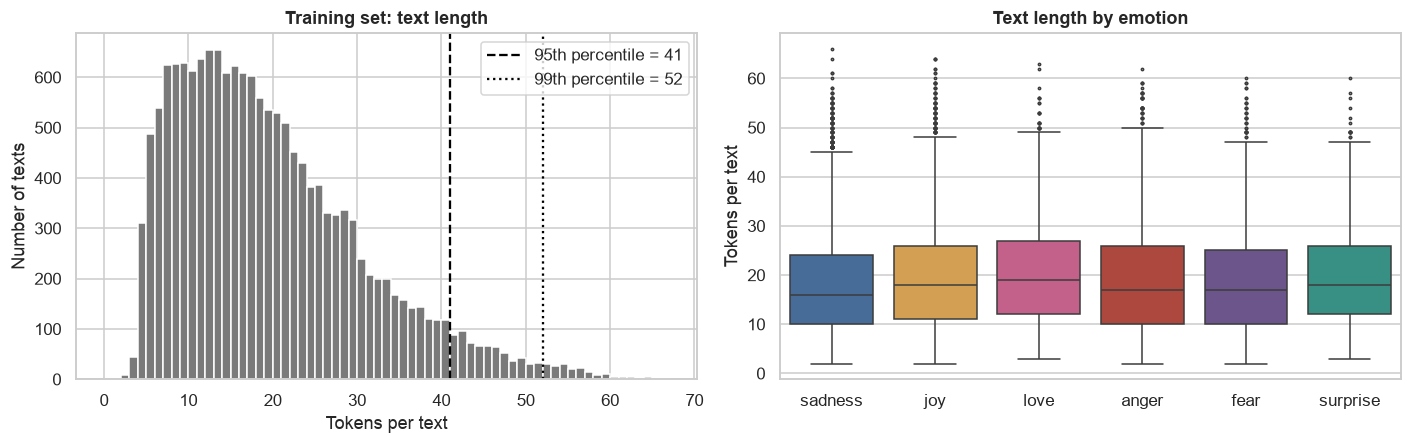

In [5]:
for df in splits.values():
    df["n_tokens"] = df["text"].map(lambda t: len(tokenize(t)))

length_stats = pd.DataFrame({name: df["n_tokens"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]) for name, df in splits.items()}).T
display(length_stats.round(1))

by_class = train.groupby("label_name")["n_tokens"].agg(["median", "mean", "std"]).reindex(LABELS)
display(by_class.round(1))

h_stat, h_p = kruskal(*[train.loc[train["label_name"] == c, "n_tokens"] for c in LABELS])
eps_sq = h_stat / (len(train) - 1)  # epsilon-squared effect size for the Kruskal-Wallis H statistic
print(f"Kruskal-Wallis test of length differences between emotions: H = {h_stat:.1f}, p = {h_p:.2g}, epsilon^2 = {eps_sq:.3f}")

p95, p99 = np.percentile(train["n_tokens"], [95, 99])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.hist(train["n_tokens"], bins=range(0, int(train["n_tokens"].max()) + 2), color="#7A7A7A", edgecolor="white")
for value, style, label in [(p95, "--", "95th percentile"), (p99, ":", "99th percentile")]:
    ax.axvline(value, color="black", linestyle=style, label=f"{label} = {value:.0f}")
ax.set_xlabel("Tokens per text")
ax.set_ylabel("Number of texts")
ax.set_title("Training set: text length")
ax.legend(loc="upper right")

ax = axes[1]
sns.boxplot(data=train, x="label_name", y="n_tokens", order=LABELS, hue="label_name",
            palette=EMOTION_COLORS, legend=False, fliersize=1.5, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Tokens per text")
ax.set_title("Text length by emotion")
fig.tight_layout()
savefig(fig, "eda_text_length.png")
plt.show()

In [6]:
# WordPiece lengths for bert-base-uncased (requires the transformers package).
try:
    from transformers import AutoTokenizer

    wp_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
    for df in splits.values():
        df["n_wordpiece"] = [len(ids) for ids in wp_tokenizer(df["text"].tolist())["input_ids"]]  # includes [CLS] and [SEP]
    wp_stats = pd.DataFrame({name: df["n_wordpiece"].describe(percentiles=[0.5, 0.95, 0.99]) for name, df in splits.items()}).T
    display(wp_stats.round(1))
    pieces_per_word = (train["n_wordpiece"] - 2).sum() / train["n_tokens"].sum()
    print(f"WordPiece tokens per word token (train, excluding [CLS]/[SEP]): {pieces_per_word:.2f}")
    for max_len in (64, 128):
        n_cut = sum(int((df["n_wordpiece"] > max_len).sum()) for df in splits.values())
        print(f"Texts (all splits) longer than max_length = {max_len}: {n_cut}")
except ImportError:
    print("transformers is not installed; the WordPiece length check is repeated in 06_bert.")

,count,mean,std,min,50%,95%,99%,max
train,16000.0,22.3,11.6,4.0,20.0,45.0,57.0,87.0
validation,2000.0,21.9,11.4,4.0,20.0,44.0,56.0,69.0
test,2000.0,22.2,11.5,5.0,20.0,45.0,55.0,66.0


WordPiece tokens per word token (train, excluding [CLS]/[SEP]): 1.06
Texts (all splits) longer than max_length = 64: 30
Texts (all splits) longer than max_length = 128: 0


**Implication.** The texts are short: the median length is 17 word tokens (mean 19.2), 95% of training texts have at most 41 tokens and the longest has 66; validation and test have almost identical length profiles. Each prediction therefore rests on little lexical evidence, and a single emotion word can decide the label. Length differs significantly between emotions (Kruskal–Wallis H = 89.3, p < 10⁻¹⁷), but the effect is negligible (ε² ≈ 0.006; class medians range only from 16 tokens for *sadness* to 19 for *love*), so length is not a useful feature on its own.

Because even the longest text is short, the sequence models do not need to truncate anything. A cut-off at the 99th percentile (52 tokens) would save little computation once batches are padded dynamically, yet it would shorten about 1% of the texts. The maximum lengths are therefore set to cover every text:

- **BiLSTM:** `MAX_LEN_LSTM = 66` word tokens (the training maximum; validation and test texts have at most 61), with per-batch padding and `pack_padded_sequence`.
- **BERT:** `MAX_LEN_BERT = 128` WordPiece tokens, including `[CLS]` and `[SEP]`, with dynamic padding. On this lower-cased, informal text WordPiece adds few pieces (1.06 pieces per word token), but the longest training text still reaches 87 pieces (99th percentile: 57), and 30 texts across the three splits exceed 64. With a maximum of 128, no text in any split is truncated.

## 4. Vocabulary, Zipf's law and unseen words

Word frequencies in natural language follow Zipf's law: frequency is roughly inversely proportional to frequency rank, so most word types are rare. This is the sparsity problem that motivates smoothing in n-gram language models (Lecture 5) and dense or sub-word representations (Lecture 6).

Training vocabulary: 15,212 word types, 306,661 tokens
Hapax legomena (types seen once): 7,813 (51.4% of types)


,OOV token rate,texts with >= 1 OOV word
split,,
validation,2.7%,31.2%
test,2.7%,31.5%


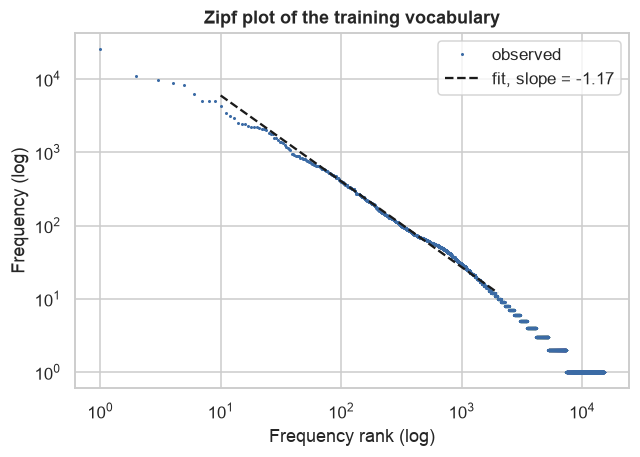

In [7]:
train_counts = Counter(tok for text in train["text"] for tok in tokenize(text))
vocab = set(train_counts)
n_hapax = sum(1 for c in train_counts.values() if c == 1)
print(f"Training vocabulary: {len(vocab):,} word types, {sum(train_counts.values()):,} tokens")
print(f"Hapax legomena (types seen once): {n_hapax:,} ({n_hapax / len(vocab):.1%} of types)")

oov_rows = []
for name in ["validation", "test"]:
    toks = [tokenize(t) for t in splits[name]["text"]]
    n_tok = sum(len(t) for t in toks)
    n_oov = sum(1 for t in toks for w in t if w not in vocab)
    has_oov = np.mean([any(w not in vocab for w in t) for t in toks])
    oov_rows.append({"split": name, "OOV token rate": n_oov / n_tok, "texts with >= 1 OOV word": has_oov})
display(pd.DataFrame(oov_rows).set_index("split").style.format("{:.1%}"))

freqs = np.array(sorted(train_counts.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
fit_range = slice(9, min(2000, len(freqs)))
slope, intercept = np.polyfit(np.log10(ranks[fit_range]), np.log10(freqs[fit_range]), 1)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.loglog(ranks, freqs, ".", markersize=2, color="#3B6BA5", label="observed")
ax.loglog(ranks[fit_range], 10 ** (intercept + slope * np.log10(ranks[fit_range])), "k--", label=f"fit, slope = {slope:.2f}")
ax.set_xlabel("Frequency rank (log)")
ax.set_ylabel("Frequency (log)")
ax.set_title("Zipf plot of the training vocabulary")
ax.legend()
savefig(fig, "eda_zipf.png")
plt.show()

**Implication.** The training vocabulary has 15,212 word types for 306,661 tokens, and 7,813 types (51.4%) occur only once; the rank–frequency curve follows Zipf's law closely (fitted log–log slope −1.17 over ranks 10–2,000). Unseen words are rare as tokens (2.7% of validation and test tokens) but common at the text level: 31.2% of validation texts and 31.5% of test texts contain at least one word that never occurs in training. A word-level bag-of-words model simply ignores these words. Character n-grams — the sub-word idea behind FastText — and BERT's WordPiece tokenizer share information across related forms (*annoy, annoyed, annoying*) and spelling variants, so they are expected to help. Because only 2.7% of tokens are affected, the size of this gain is measured in a controlled experiment rather than assumed.

## 5. Frequent versus distinctive words

Raw frequency mostly surfaces function words that occur in every class. To find words that *distinguish* an emotion, each class is compared with all other classes using the **weighted log-odds ratio with an informative Dirichlet prior** (Monroe, Colaresi & Quinn, 2008). The z-score accounts for the uncertainty of rare words, so it does not over-rank words that appear only a handful of times.

In [8]:
class_counts = {c: Counter(tok for text in train.loc[train["label_name"] == c, "text"] for tok in tokenize(text)) for c in LABELS}

top_frequent = pd.DataFrame({c: [w for w, _ in class_counts[c].most_common(12)] for c in LABELS})
stop_share = top_frequent.isin(ENGLISH_STOP_WORDS).mean()
print("Share of stop words among the 12 most frequent words per class:")
print(stop_share.round(2).to_string())
top_frequent

Share of stop words among the 12 most frequent words per class:
sadness     0.83
joy         0.83
love        0.75
anger       0.83
fear        0.83
surprise    0.83


,sadness,joy,love,anger,fear,surprise
0,i,i,i,i,i,i
1,feel,feel,feel,feel,feel,feel
2,and,and,and,and,to,and
3,to,to,to,to,and,the
4,the,the,the,the,the,to
5,a,a,a,a,a,a
6,feeling,that,of,feeling,feeling,that
7,of,of,that,that,of,feeling
8,that,feeling,my,of,that,of
9,my,my,feeling,my,my,my


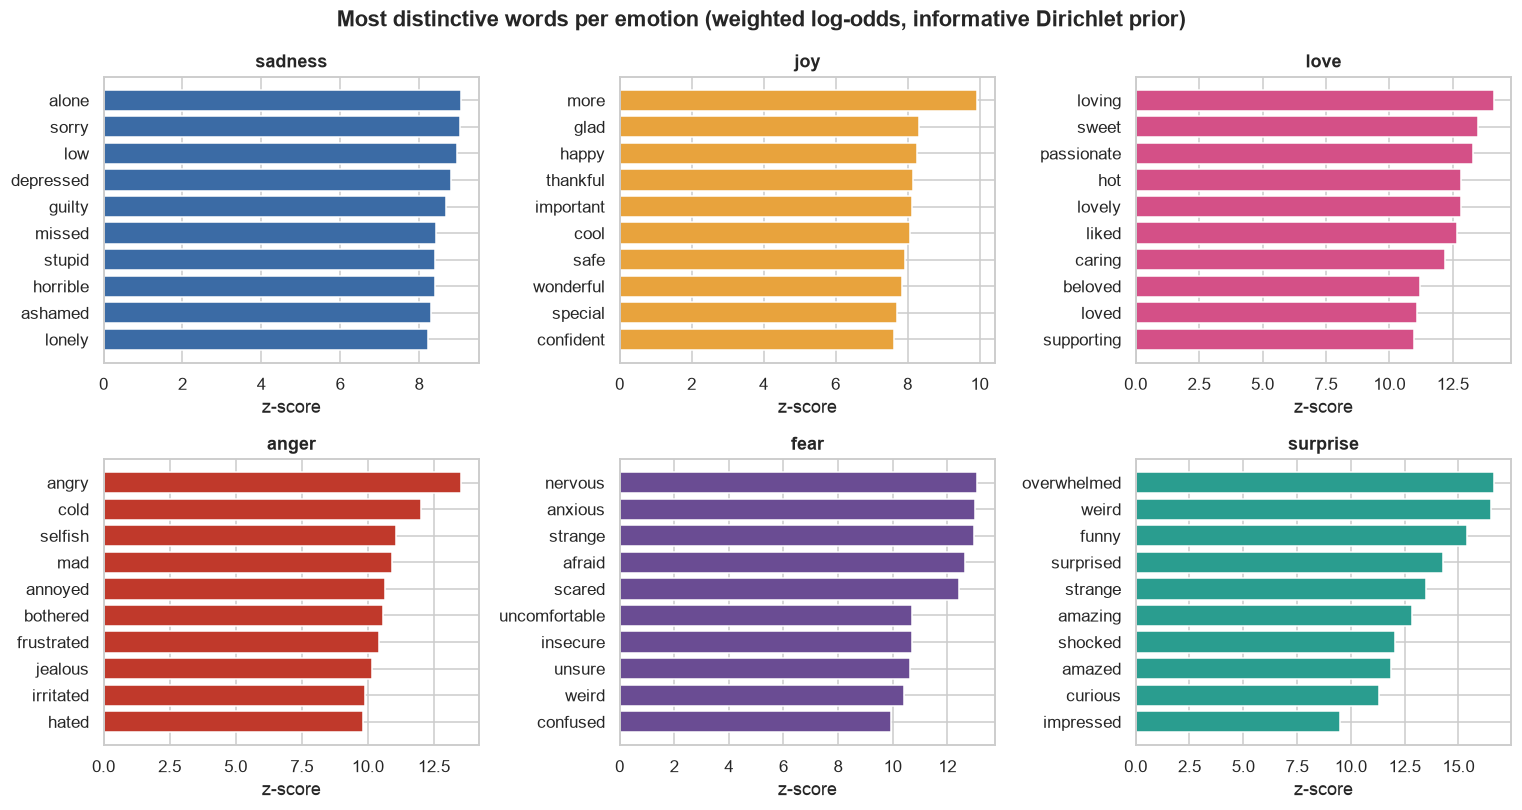

,sadness,joy,love,anger,fear,surprise
0,alone,more,loving,angry,nervous,overwhelmed
1,sorry,glad,sweet,cold,anxious,weird
2,low,happy,passionate,selfish,strange,funny
3,depressed,thankful,hot,mad,afraid,surprised
4,guilty,important,lovely,annoyed,scared,strange
5,missed,cool,liked,bothered,uncomfortable,amazing
6,stupid,safe,caring,frustrated,insecure,shocked
7,horrible,wonderful,beloved,jealous,unsure,amazed
8,ashamed,special,loved,irritated,weird,curious
9,lonely,confident,supporting,hated,confused,impressed


In [9]:
def log_odds_dirichlet(counts_i, counts_j, prior, alpha0=1000):
    # Weighted log-odds ratio (class i vs. class j) with an informative Dirichlet prior
    # proportional to overall word frequency (Monroe et al., 2008, eq. 22).
    n_i, n_j, n_prior = sum(counts_i.values()), sum(counts_j.values()), sum(prior.values())
    scores = {}
    for w, p in prior.items():
        a_w = alpha0 * p / n_prior
        y_i, y_j = counts_i.get(w, 0), counts_j.get(w, 0)
        delta = np.log((y_i + a_w) / (n_i + alpha0 - y_i - a_w)) - np.log((y_j + a_w) / (n_j + alpha0 - y_j - a_w))
        scores[w] = delta / np.sqrt(1 / (y_i + a_w) + 1 / (y_j + a_w))
    return pd.Series(scores)


MIN_COUNT = 10
prior = Counter({w: c for w, c in train_counts.items() if c >= MIN_COUNT})
distinctive = {}
for c in LABELS:
    rest = Counter()
    for other in LABELS:
        if other != c:
            rest.update(class_counts[other])
    distinctive[c] = log_odds_dirichlet(class_counts[c], rest, prior).sort_values(ascending=False)

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, c in zip(axes.flat, LABELS):
    top = distinctive[c].head(10)[::-1]
    ax.barh(top.index, top.values, color=EMOTION_COLORS[c])
    ax.set_title(c)
    ax.set_xlabel("z-score")
fig.suptitle("Most distinctive words per emotion (weighted log-odds, informative Dirichlet prior)", fontweight="bold")
fig.tight_layout()
savefig(fig, "eda_distinctive_words.png")
plt.show()

pd.DataFrame({c: distinctive[c].head(10).index for c in LABELS})

**Implication.** Raw frequencies carry almost no class information: in every class the two most frequent words are *i* and *feel*, and 9–10 of the 12 most frequent words are stop words (75–83%). This motivates TF-IDF weighting (Lecture 6), which down-weights terms that occur in most documents. The distinctive words, by contrast, are almost all emotion adjectives (*alone, depressed* for sadness; *glad, thankful* for joy; *nervous, anxious* for fear), which explains why linear models over sparse word features are strong baselines on this dataset (other complex models are not necessarily better). Two observations anticipate later errors. First, *fear* and *surprise* share distinctive words (*strange* and *weird* appear in both top-10 lists), so this pair is expected to be confusable. Second, some distinctive words are not emotion terms in their usual sense — *cold* for anger, *hot* for love, *more* and *important* for joy — which suggests that labels sometimes follow a query word rather than the emotion expressed (see §6–§8).

## 6. Lexical templates left by data collection

The CARER corpus was collected from social-media posts using emotion-related queries and hashtags (Saravia et al., 2018). A trace of that procedure would appear as a recurring sentence template. The table counts, per emotion, the texts that contain a form of *feel* and the texts that begin with *"i feel"*, followed by the most common sentence openings.

In [10]:
FEEL_RE = re.compile(r"\b(?:feel|feels|feeling|felt)\b")

template = pd.DataFrame({
    "contains feel/feeling/felt": train.groupby("label_name")["text"].apply(lambda s: s.str.contains(FEEL_RE).mean()),
    "starts with 'i feel'": train.groupby("label_name")["text"].apply(lambda s: s.str.startswith("i feel").mean()),
}).reindex(LABELS)
template.loc["all classes"] = [train["text"].str.contains(FEEL_RE).mean(), train["text"].str.startswith("i feel").mean()]
display(template.style.format("{:.1%}"))

openings = Counter(" ".join(tokenize(t)[:2]) for t in train["text"])
print("Most common sentence openings:", ", ".join(f"'{o}' ({n:,})" for o, n in openings.most_common(8)))

,contains feel/feeling/felt,starts with 'i feel'
label_name,,
sadness,98.0%,32.6%
joy,97.8%,33.8%
love,96.9%,33.4%
anger,95.0%,31.2%
fear,96.7%,25.3%
surprise,98.3%,28.8%
all classes,97.3%,31.9%


Most common sentence openings: 'i feel' (5,072), 'i am' (925), 'i was' (660), 'im feeling' (587), 'i have' (536), 'i can' (281), 'i know' (243), 'i just' (240)


**Implication.** Almost every text (97.3%) contains a form of *feel*, and about a third begin with *"i feel"* (31.9% overall, from 25.3% for *fear* to 33.8% for *joy*); *"i feel"* is by far the most common opening (5,072 texts), followed by *"i am"* (925) and *"i was"* (660). This uniformity is consistent with texts retrieved through emotion-related queries (Saravia et al., 2018) rather than sampled from everyday posts. Combined with the distinctive words in §5, which are almost all emotion adjectives, it means that the label often hinges on a single word in the frame *"feel + adjective"*. This makes the task easy for lexical models but creates a risk of **shortcut learning**: a model can learn adjective–label associations without handling negation (*"i don't feel happy"*), intensity or irony. It also implies a domain shift for the web application, where users rarely phrase their input in this frame. §8.1 measures how much harder texts outside the template and texts with negation are, and the error analysis returns to both risks with behavioural tests.

## 7. Duplicates, label conflicts and overlap between splits

Exact duplicate texts with *different* labels are direct evidence of label noise, and texts shared between training and evaluation splits would inflate the reported scores. For the test split only the number of overlapping texts is reported; test labels are not inspected.

In [11]:
dup_mask = train["text"].duplicated(keep=False)
conflicts = train[dup_mask].groupby("text")["label_name"].agg(lambda s: sorted(set(s)))
conflicts = conflicts[conflicts.map(len) > 1]
print(f"Training texts that occur more than once: {int(dup_mask.sum()):,} rows ({train.loc[dup_mask, 'text'].nunique():,} distinct texts)")
print(f"Duplicated texts with conflicting labels: {len(conflicts):,}")
display(conflicts.head(8).to_frame("labels"))

train_texts = set(train["text"])
overlap = pd.Series({
    "train ∩ validation": len(train_texts & set(val["text"])),
    "train ∩ test": len(train_texts & set(test["text"])),
    "validation ∩ test": len(set(val["text"]) & set(test["text"])),
}, name="shared texts")
display(overlap.to_frame())

shared_val = val[val["text"].isin(train_texts)].merge(
    train.drop_duplicates("text")[["text", "label_name"]], on="text", suffixes=("_val", "_train"))
if len(shared_val):
    agree = (shared_val["label_name_val"] == shared_val["label_name_train"]).mean()
    print(f"Label agreement on texts shared by train and validation: {agree:.1%} of {len(shared_val)}")

Training texts that occur more than once: 62 rows (31 distinct texts)
Duplicated texts with conflicting labels: 30


,labels
text,
i am not amazing or great at photography but i feel passionate about it,"[joy, love]"
i began to feel accepted by gaia on her own terms,"[joy, love]"
i bet taylor swift basks in the knowledge that the boys she writes songs about probably feel tortured,"[anger, fear]"
i cant escape the tears of sadness and just true grief i feel at the loss of my sweet friend and sister,"[joy, love]"
i could feel myself hit this strange foggy wall,"[fear, surprise]"
i feel a remembrance of the strange by justin aryiku falls into the latter category,"[fear, surprise]"
i feel im being generous with that statement,"[joy, love]"
i feel kind of strange,"[fear, surprise]"


,shared texts
train ∩ validation,5
train ∩ test,11
validation ∩ test,3


Label agreement on texts shared by train and validation: 0.0% of 5


**Implication.** Exact duplicates are rare — 31 distinct texts occur twice in the training set — but 30 of these 31 carry two different labels, mostly between neighbouring emotions (*joy/love*, *fear/surprise*). The same text was apparently retrieved under two emotion queries and inherited both labels, which is direct evidence that the labels come from distant supervision rather than from a reader's judgement. The direct cost is negligible (at most 30 of 16,000 training texts, 0.19%, cannot be fitted), but the conflicts motivate a *dataset label noise* category in the error analysis, where the model's prediction may be more defensible than the gold label. Overlap between splits is minimal: 5 texts are shared by train and validation, 11 by train and test, and 3 by validation and test. All 5 train–validation pairs carry different labels, so the overlap cannot inflate validation scores; if anything it lowers them slightly.

## 8. Ambiguous and difficult-to-classify texts

To locate intrinsically difficult examples without touching the evaluation splits, a simple **probe** — TF-IDF features with logistic regression — is trained with 5-fold stratified cross-validation **on the training set only**. Every training text therefore receives a prediction from a model that did not see it. Texts that receive a low probability for their own gold label are either ambiguous, express several emotions, or are mislabelled. The probe is a diagnostic tool, not one of the compared models.

,cv_recall,mean_gold_prob
label_name,,
sadness,0.919,0.580
joy,0.960,0.607
love,0.416,0.309
anger,0.656,0.407
fear,0.635,0.393
surprise,0.259,0.223


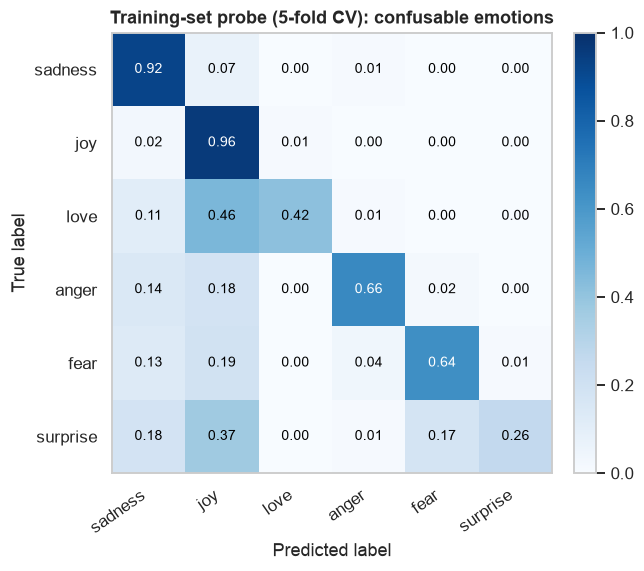

In [12]:
probe = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=2000, random_state=SEED),
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_proba = cross_val_predict(probe, train["text"], train["label"], cv=cv, method="predict_proba", n_jobs=-1)
train["cv_pred"] = cv_proba.argmax(axis=1)
train["gold_prob"] = cv_proba[np.arange(len(train)), train["label"]]
train["cv_pred_name"] = train["cv_pred"].map(dict(enumerate(LABELS)))

difficulty = train.groupby("label_name").agg(cv_recall=("cv_pred", lambda s: (s == train.loc[s.index, "label"]).mean()),
                                             mean_gold_prob=("gold_prob", "mean")).reindex(LABELS)
display(difficulty.round(3))

fig, ax = plt.subplots(figsize=(6.4, 5.2))
plot_confusion_matrix(train["label"], train["cv_pred"], title="Training-set probe (5-fold CV): confusable emotions", ax=ax,
                      save_as="eda_probe_confusion.png")
plt.show()

In [13]:
likely_noise = train[(train["gold_prob"] < 0.05) & (cv_proba.max(axis=1) > 0.90)]
print(f"Confidently contradicted labels (gold prob < 0.05, probe confidence > 0.90): {len(likely_noise):,} "
      f"({len(likely_noise) / len(train):.1%} of training texts)")

hardest = train.nsmallest(12, "gold_prob")[["text", "label_name", "cv_pred_name", "gold_prob"]]
hardest.columns = ["text", "gold label", "probe prediction", "P(gold)"]
hardest.style.format({"P(gold)": "{:.3f}"})

Confidently contradicted labels (gold prob < 0.05, probe confidence > 0.90): 3 (0.0% of training texts)


,text,gold label,probe prediction,P(gold)
12760,i feel agitated im nervous im anxious,anger,fear,0.011
6094,im feeling quite agitated irritated amp annoyed,fear,anger,0.020
2067,i felt disgust of dirty,anger,sadness,0.024
3987,i feel like in spite of having so many amazing things to be thankful for life is just one big demanding wave after wave and i m being tossed around like a rag doll,surprise,joy,0.032
15371,ive seen how mean other kids and adults can be to a child who doesnt fit into the norm and no way was i going to label him so he could be made to feel he was anything other than amazing,surprise,joy,0.034
9947,i feel ludicrous even thinking these things,surprise,sadness,0.034
6352,i dont want to put to much pressure on myself but i feel like i could make the most amazing year ever,surprise,joy,0.036
12933,i started going down the adventure feeling totally ludicrous and wondering if this wasnt all just a waste of my time thats when i saw this screenshot,surprise,sadness,0.038
10439,i am nowhere near finished but how much better do i feel its ludicrous,surprise,joy,0.040
3995,i feel too overwhelmed to clean anything so i just let it all pile up until it makes my whole life feel like it is going to come crashing down around me and i am helpless to stop it,surprise,fear,0.041


**Implication.** Difficulty is concentrated in the minority classes. Under 5-fold cross-validation the probe recovers *joy* (96.0%) and *sadness* (91.9%) almost perfectly, but only 65.6% of *anger*, 63.5% of *fear*, 41.6% of *love* and 25.9% of *surprise*. Errors flow mainly towards the two majority classes: 46% of *love* texts are predicted as *joy*, *surprise* is spread over *joy* (37%), *sadness* (18%) and *fear* (17%), and even *anger* and *fear* lose about a third of their texts to *joy* and *sadness*. This pattern reflects both semantic overlap and the class prior learned by an unweighted classifier, which is why class weighting is tested in the improved models.

The lowest-probability texts show three sources of difficulty that structure the later error analysis:

1. **Several emotions in one text.** *"i feel agitated im nervous im anxious"* is labelled *anger*, while the near-identical *"im feeling quite agitated irritated amp annoyed"* is labelled *fear*.
2. **Negated or implicit emotion.** *"not feeling particularly enthralled about the educational tour"* is labelled *surprise*.
3. **Labels that follow a single query word rather than the meaning.** Eight of the twelve hardest texts are labelled *surprise*, typically because they contain *amazing*, *ludicrous* or *overwhelmed* in an otherwise joyful or distressed context.

Only 3 training texts (0.02%) are contradicted with a probe confidence above 0.90, so the label noise lies mainly at class boundaries rather than in random label flips.

### 8.1 Slice analysis: sentence template and negation

The cross-validated probe predictions from §8 are reused to compare two pairs of training-set slices: texts by **template** (beginning with *"i feel"*, containing *feel* elsewhere, or containing no form of *feel*) and texts **with or without a negation cue** (*not, no, never, dont, cant, …*; the dataset has no apostrophes, so both *dont* and *don t* are matched). Lower scores outside the template indicate reliance on the *"feel + adjective"* frame and anticipate the domain shift of free-form input in the web application; lower scores with negation indicate that the bag-of-words probe ignores the scope of negation.

Because the label mix differs between slices, macro-F1 is reported with a 95% bootstrap confidence interval (1,000 resamples), and recall is also broken down by emotion (cells with fewer than 20 texts are left blank). This analysis uses training-set cross-validation only; no evaluation split is involved.

Label mix and per-class recall by template:


Label mix and per-class recall by negation:


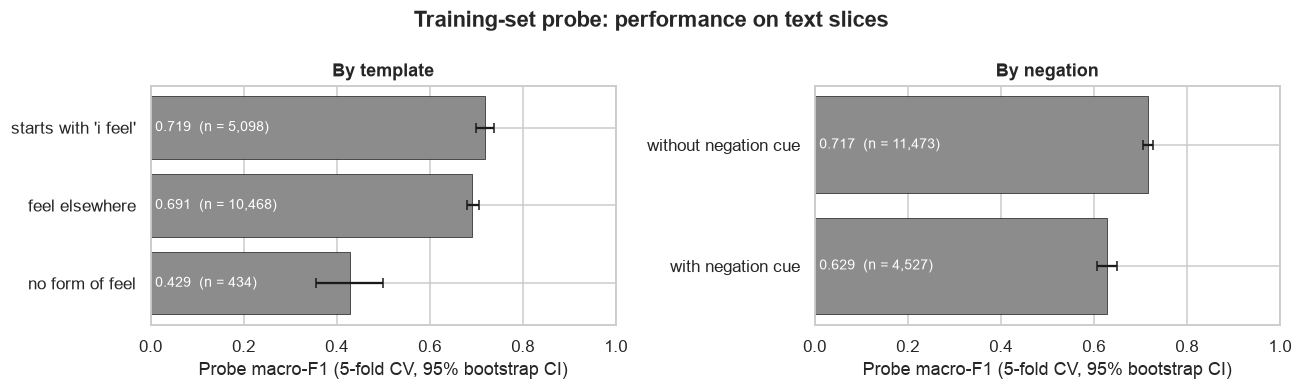

In [14]:
NEGATION_RE = re.compile(
    r"\b(?:not|no|never|nothing|nobody|none|nor|without|hardly|cannot|cant|dont|didnt|doesnt|isnt|wasnt|arent|werent"
    r"|wont|wouldnt|couldnt|shouldnt|havent|hasnt|hadnt|aint)\b"
    r"|\b(?:don|didn|doesn|isn|wasn|aren|weren|won|wouldn|couldn|shouldn|haven|hasn|hadn|can|ain)\s+t\b"
)
TEMPLATE_LEVELS = ["starts with 'i feel'", "feel elsewhere", "no form of feel"]
NEGATION_LEVELS = ["without negation cue", "with negation cue"]

train["template"] = np.select(
    [train["text"].str.startswith("i feel"), train["text"].str.contains(FEEL_RE)], TEMPLATE_LEVELS[:2], default=TEMPLATE_LEVELS[2])
train["negation"] = np.where(train["text"].str.contains(NEGATION_RE), NEGATION_LEVELS[1], NEGATION_LEVELS[0])


def probe_macro_f1(y, p):
    return f1_score(y, p, labels=list(range(len(LABELS))), average="macro", zero_division=0)


rng = np.random.default_rng(SEED)
rows = []
for factor, levels in [("template", TEMPLATE_LEVELS), ("negation", NEGATION_LEVELS)]:
    for level in levels:
        part = train[train[factor] == level]
        y, p = part["label"].to_numpy(), part["cv_pred"].to_numpy()
        boot = [probe_macro_f1(y[idx], p[idx]) for idx in (rng.integers(0, len(y), len(y)) for _ in range(1000))]
        rows.append({"factor": factor, "slice": level, "n": len(part), "share of train": len(part) / len(train),
                     "accuracy": (y == p).mean(), "macro-F1": probe_macro_f1(y, p),
                     "CI low": np.percentile(boot, 2.5), "CI high": np.percentile(boot, 97.5)})
slices = pd.DataFrame(rows).set_index(["factor", "slice"])
display(slices.style.format({"n": "{:,}", "share of train": "{:.1%}", "accuracy": "{:.3f}",
                             "macro-F1": "{:.3f}", "CI low": "{:.3f}", "CI high": "{:.3f}"}))


def recall_by_class(factor, levels, min_n=20):
    # Per-class recall within each slice; this controls for differences in label mix between slices.
    grouped = (train.assign(correct=train["label"] == train["cv_pred"])
               .groupby([factor, "label_name"])["correct"].agg(["mean", "size"]))
    return grouped["mean"].where(grouped["size"] >= min_n).unstack().reindex(index=levels, columns=LABELS)


for factor, levels in [("template", TEMPLATE_LEVELS), ("negation", NEGATION_LEVELS)]:
    print(f"Label mix and per-class recall by {factor}:")
    mix = pd.crosstab(train[factor], train["label_name"], normalize="index").reindex(index=levels, columns=LABELS)
    display(pd.concat({"label share": mix, "recall": recall_by_class(factor, levels)}, axis=1).style.format("{:.2f}", na_rep="–"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
for ax, factor in zip(axes, ["template", "negation"]):
    part = slices.loc[factor]
    ax.barh(part.index[::-1], part["macro-F1"][::-1], color="#8C8C8C", edgecolor="black", linewidth=0.4,
            xerr=[(part["macro-F1"] - part["CI low"])[::-1], (part["CI high"] - part["macro-F1"])[::-1]], capsize=3)
    for k, (f1, n) in enumerate(zip(part["macro-F1"][::-1], part["n"][::-1])):
        ax.text(0.01, k, f"{f1:.3f}  (n = {n:,})", va="center", fontsize=9, color="white")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Probe macro-F1 (5-fold CV, 95% bootstrap CI)")
    ax.set_title(f"By {factor}")
fig.suptitle("Training-set probe: performance on text slices", fontweight="bold")
fig.tight_layout()
savefig(fig, "eda_slices.png")
plt.show()

**Implication.** Two slices are clearly harder for the probe.

- **Texts without any form of *feel*** (434 texts, 2.7% of the training set). Macro-F1 falls from 0.719 for texts beginning with *"i feel"* to 0.429 (95% CI 0.357–0.500), and accuracy from 82.6% to 52.3%. The drop is not an artefact of label mix: although this slice contains more *anger* (25% vs. 13%), recall is lower for every emotion, most sharply for *anger* (0.25 vs. 0.70) and *fear* (0.10 vs. 0.63). Whether *feel* appears at the start or elsewhere in the text matters much less (0.719 vs. 0.691, overlapping intervals). The probe therefore relies heavily on the *"feel + adjective"* frame. Because input typed or spoken in the web application rarely follows this frame, performance there is likely to be considerably lower than test-set scores suggest; this limitation is stated in the model card, and template-free sentences are included in the behavioural tests.
- **Texts with a negation cue** (4,527 texts, 28.3%). Macro-F1 drops from 0.717 to 0.629, and the confidence intervals do not overlap. The two slices have almost the same label mix, yet recall falls for every emotion, most for the minority classes (*love* 0.45 → 0.32, *surprise* 0.29 → 0.17). Even with word bigrams, a bag-of-words model does not represent the scope of negation. Not every cue negates the emotion itself (*"i dont know why but i feel happy"*), so this comparison indicates rather than isolates the effect; controlled negation pairs are examined in the behavioural tests.

The same slices are reused in the error analysis (08) to compare all models on the test set: a model that captures context beyond the template, such as the BiLSTM or BERT, should narrow both gaps.

## 9. Sanity check of the evaluation pipeline

Before training real models, `src/evaluate.py` is checked on two trivial classifiers on the **validation** set. They also give a performance floor: any useful model must clearly exceed them, especially on macro-F1.

In [15]:
X_train_dummy = np.zeros((len(train), 1))
X_val_dummy = np.zeros((len(val), 1))
for strategy in ["most_frequent", "stratified"]:
    dummy = DummyClassifier(strategy=strategy, random_state=SEED).fit(X_train_dummy, train["label"])
    record = evaluate(f"dummy_{strategy}", val["label"], dummy.predict(X_val_dummy), split="validation",
                      texts=val["text"], notes=f"DummyClassifier(strategy='{strategy}'); sanity check")
per_class_table(record).round(3)

dummy_most_frequent [validation]  accuracy=0.3520  macro-F1=0.0868  weighted-F1=0.1833
dummy_stratified [validation]  accuracy=0.2435  macro-F1=0.1712  weighted-F1=0.2445


,precision,recall,f1,support
sadness,0.294,0.300,0.297,550.0
joy,0.356,0.342,0.349,704.0
love,0.095,0.090,0.092,178.0
anger,0.142,0.145,0.144,275.0
fear,0.089,0.099,0.094,212.0
surprise,0.054,0.049,0.052,81.0


**Implication.** The evaluation pipeline works end to end and gives the performance floor for every later model. Always predicting the majority class (*joy*) reaches 35.2% accuracy but only 0.087 macro-F1, because it scores zero on five of the six classes; a random classifier that follows the training label distribution reaches 0.171 macro-F1 at 24.4% accuracy. The contrast between the two metrics on the majority-class classifier is the clearest argument for macro-F1 as the selection metric. The per-class table above refers to the stratified classifier.

## 10. Summary of findings and implications for modelling

In [16]:
summary = {
    "Training texts": f"{len(train):,}",
    "Largest / smallest class (train)": f"{dist['train'].idxmax()} {share['train'].max():.1%} / {dist['train'].idxmin()} {share['train'].min():.1%}",
    "Imbalance ratio": f"{imbalance_ratio:.1f}",
    "Median / 99th percentile / maximum length (tokens)": f"{train['n_tokens'].median():.0f} / {p99:.0f} / {train['n_tokens'].max()}",
    "Training vocabulary (types)": f"{len(vocab):,}",
    "Hapax share of types": f"{n_hapax / len(vocab):.1%}",
    "Test texts with >= 1 unseen word": f"{oov_rows[1]['texts with >= 1 OOV word']:.1%}",
    "Texts containing a form of 'feel'": f"{template.loc['all classes', 'contains feel/feeling/felt']:.1%}",
    "Duplicated texts with conflicting labels": f"{len(conflicts):,} of {train.loc[dup_mask, 'text'].nunique():,}",
    "Probe: confidently contradicted labels": f"{len(likely_noise):,} ({len(likely_noise) / len(train):.2%})",
    "Probe: hardest class (lowest CV recall)": f"{difficulty['cv_recall'].idxmin()} ({difficulty['cv_recall'].min():.1%})",
}
pd.Series(summary, name="value").to_frame()

,value
Training texts,"16,000"
Largest / smallest class (train),joy 33.5% / surprise 3.6%
Imbalance ratio,9.4
Median / 99th percentile / maximum length (tokens),17 / 52 / 66
Training vocabulary (types),"15,212"
Hapax share of types,51.4%
Test texts with >= 1 unseen word,31.5%
Texts containing a form of 'feel',97.3%
Duplicated texts with conflicting labels,30 of 31
Probe: confidently contradicted labels,3 (0.02%)


| Finding | Evidence | Implication for model development |
|---|---|---|
| Strong class imbalance | *joy* 33.5% vs. *surprise* 3.6% (ratio 9.4); majority-class baseline: 35.2% accuracy but 0.087 macro-F1 | Macro-F1 as the primary selection metric; class weighting tested as a controlled experiment; per-class scores always reported. |
| Comparable splits | Same label distribution (χ² = 11.21, p = 0.34) and length profile | Validation is a reliable proxy for test; the test set is used once, at the end. |
| Short texts | Median 17 word tokens (max 66); WordPiece: median 20, 99th percentile 57, max 87 | No truncation needed: BiLSTM `MAX_LEN_LSTM = 66` word tokens, BERT `MAX_LEN_BERT = 128` WordPiece tokens (64 would truncate 30 texts), both with dynamic padding. |
| Zipfian, sparse vocabulary | 51.4% of types are hapaxes; 31.5% of test texts contain an unseen word (2.7% of tokens) | Character n-grams (FastText-style sub-words) and WordPiece are expected to help; the gain is tested, not assumed. |
| Function words dominate frequencies; emotion adjectives are distinctive | 75–83% stop words among the 12 most frequent words per class | TF-IDF weighting over raw counts; linear models over sparse features are strong baselines. |
| *"feel"* template from data collection | 97.3% of texts contain *feel*; 31.9% begin with *"i feel"* | Labels often hinge on one adjective → risk of shortcut learning; negation, intensity and irony are tested with behavioural tests; domain shift for the web app is noted in the model card. |
| Label noise from distant supervision | 30 of 31 duplicated texts have conflicting labels; hardest texts are labelled by a single query word (*amazing → surprise*) | Label noise limits the achievable score and is analysed as a separate error category. |
| Minority classes are absorbed by majority classes | Probe CV recall: *surprise* 25.9%, *love* 41.6%; 46% of *love* predicted as *joy* | Expect *love → joy* and *surprise → joy / sadness / fear* to dominate the confusion matrices. |
| Dependence on the *feel* template and on negation | Probe macro-F1: 0.719 for *"i feel …"* texts vs. 0.429 without *feel*; 0.717 without vs. 0.629 with a negation cue | Behavioural tests with template-free and negated sentences; slice scores reported for every model in the error analysis; domain shift of app input stated in the model card. |